
# Lab Sheet 3 – Developing a Tiny Transformer Language Model

## Objective
To build, train, and evaluate a small Transformer language model using the TinyStories dataset for next-token prediction and story generation.


In [1]:


import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


%pip -q install datasets
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)


Libraries imported successfully!
PyTorch version: 2.14.1+cu130
Device: cuda


In [2]:

# Load 1,000 stories from the training dataset
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

print("Dataset loaded successfully!")
print("Total stories:", len(dataset))

# Display the first story
print("\nFirst Story:")
print(dataset[0]["text"])


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Dataset loaded successfully!
Total stories: 1000

First Story:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.


In [3]:

# Calculate story lengths
story_lengths = [len(story["text"]) for story in dataset]

print("Total stories:", len(dataset))
print("Shortest story:", min(story_lengths), "characters")
print("Longest story:", max(story_lengths), "characters")
print("Average story length:", round(np.mean(story_lengths), 2), "characters")

# Display samples from the dataset
for i in range(3):
    print(f"\n--- Story {i + 1} ---")
    print(dataset[i]["text"][:300])


Total stories: 1000
Shortest story: 274 characters
Longest story: 4123 characters
Average story length: 941.64 characters

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and 

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Bee

--- Story 3 ---
One day, a little fish named Fin was swimming near the shore. He saw a big crab and wanted to be friends. "Hi, I am Fin. Do you want to play?" asked the little fish. The crab looked at Fin and said, "No, I don't want to play.

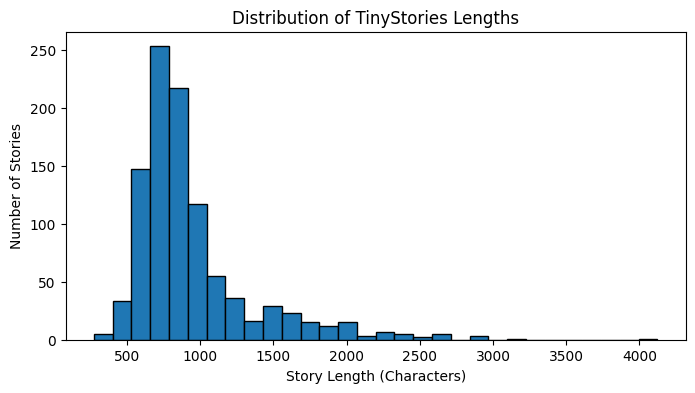

In [4]:

plt.figure(figsize=(8, 4))
plt.hist(story_lengths, bins=30, edgecolor="black")
plt.title("Distribution of TinyStories Lengths")
plt.xlabel("Story Length (Characters)")
plt.ylabel("Number of Stories")
plt.show()


In [5]:

# Combine all stories into one text
text = "\n".join(story["text"] for story in dataset)

# Create a vocabulary of unique characters
chars = sorted(set(text))
vocab_size = len(chars)

# Map characters to numerical IDs
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

# Functions to encode and decode text
def encode(s):
    return [stoi[c] for c in s]

def decode(tokens):
    return "".join(itos[i] for i in tokens)

# Convert text into tokens
encoded_text = torch.tensor(encode(text), dtype=torch.long)

print("Total characters:", len(text))
print("Vocabulary size:", vocab_size)
print("First 20 tokens:", encoded_text[:20].tolist())
print("Decoded text:", decode(encoded_text[:50].tolist()))


Total characters: 942639
Vocabulary size: 75
First 20 tokens: [31, 56, 47, 1, 46, 43, 67, 6, 1, 43, 1, 54, 51, 62, 62, 54, 47, 1, 49, 51]
Decoded text: One day, a little girl named Lily found a needle i


In [6]:

# Split data into training and validation sets
n = int(0.9 * len(encoded_text))

train_data = encoded_text[:n]
val_data = encoded_text[n:]

block_size = 64
batch_size = 32

def get_batch(split):
    data = train_data if split == "train" else val_data

    ix = torch.randint(
        len(data) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1] for i in ix
    ])

    return x.to(device), y.to(device)

# Test batch generation
x, y = get_batch("train")

print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))
print("Input batch shape:", x.shape)
print("Target batch shape:", y.shape)

print("\nFirst 10 input tokens:", x[0][:10].tolist())
print("First 10 target tokens:", y[0][:10].tolist())


Training characters: 848375
Validation characters: 94264
Input batch shape: torch.Size([32, 64])
Target batch shape: torch.Size([32, 64])

First 10 input tokens: [49, 57, 1, 57, 56, 1, 43, 56, 1, 43]
First 10 target tokens: [57, 1, 57, 56, 1, 43, 56, 1, 43, 46]


In [7]:

# Transformer configuration
n_embd = 64
n_head = 4
n_layer = 2
dropout = 0.1

class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=n_embd,
            num_heads=n_head,
            dropout=dropout,
            batch_first=True
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        T = x.size(1)

        # Mask future characters
        mask = torch.triu(
            torch.ones(T, T, device=x.device),
            diagonal=1
        ).bool()

        attention_output, _ = self.attention(
            x, x, x,
            attn_mask=mask,
            need_weights=False
        )

        # Residual connections and normalization
        x = self.ln1(x + attention_output)
        x = self.ln2(x + self.feed_forward(x))

        return x


class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(n_layer)]
        )

        self.ln_final = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        token_emb = self.token_embedding(idx)
        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding(pos)

        x = token_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_final(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(B * T, vocab_size),
                targets.reshape(B * T)
            )

        return logits, loss


In [8]:

# Initialize the Transformer
model = TinyTransformer().to(device)

# Create optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

# Count model parameters
total_params = sum(p.numel() for p in model.parameters())

print("Transformer initialized successfully!")
print("Device:", device)
print("Total parameters:", total_params)

# Test the model
x, y = get_batch("train")
logits, loss = model(x, y)

print("Output shape:", logits.shape)
print("Initial loss:", loss.item())


Transformer initialized successfully!
Device: cuda
Total parameters: 113867
Output shape: torch.Size([32, 64, 75])
Initial loss: 4.481531143188477


In [9]:

# Training configuration
max_iters = 500
eval_interval = 100
eval_batches = 20

train_losses = []
val_losses = []
steps = []

# Function to evaluate model
@torch.no_grad()
def estimate_loss():
    results = {}

    model.eval()

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_batches):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()
    return results

# Training loop
model.train()

for step in range(max_iters + 1):

    if step % eval_interval == 0:
        losses = estimate_loss()

        steps.append(step)
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        print(
            f"Step {step}: "
            f"Train Loss = {losses['train']:.4f}, "
            f"Validation Loss = {losses['val']:.4f}"
        )

    if step == max_iters:
        break

    xb, yb = get_batch("train")

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print("\nTraining completed successfully!")


Step 0: Train Loss = 4.4894, Validation Loss = 4.4960
Step 100: Train Loss = 2.4769, Validation Loss = 2.4719
Step 200: Train Loss = 2.3175, Validation Loss = 2.3135
Step 300: Train Loss = 2.2054, Validation Loss = 2.1887
Step 400: Train Loss = 2.1073, Validation Loss = 2.0816
Step 500: Train Loss = 2.0045, Validation Loss = 1.9884

Training completed successfully!


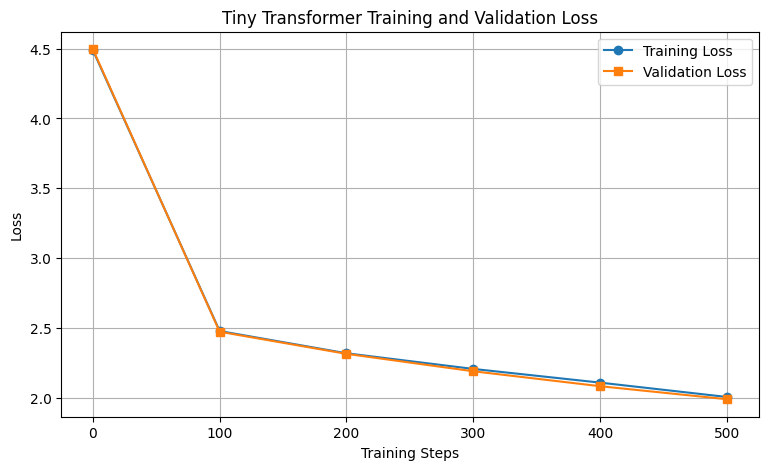

In [10]:

# Plot training and validation losses
plt.figure(figsize=(9, 5))

plt.plot(steps, train_losses, marker="o", label="Training Loss")
plt.plot(steps, val_losses, marker="s", label="Validation Loss")

plt.title("Tiny Transformer Training and Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()


In [11]:

# Generate text using the trained Transformer
@torch.no_grad()
def generate_text(model, start_text, max_new_tokens=300):
    model.eval()

    tokens = torch.tensor(
        [encode(start_text)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        # Keep only the last block_size tokens
        idx_cond = tokens[:, -block_size:]

        # Predict the next character
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]

        # Convert predictions to probabilities
        probs = F.softmax(logits, dim=-1)

        # Sample the next character
        next_token = torch.multinomial(
            probs, num_samples=1
        )

        tokens = torch.cat(
            (tokens, next_token), dim=1
        )

    return decode(tokens[0].tolist())


# Generate a new story
generated_story = generate_text(
    model,
    start_text="Once upon a time",
    max_new_tokens=300
)

print("GENERATED STORY:\n")
print(generated_story)


GENERATED STORY:

Once upon a timed, "Hen yooay. Sudily as Biomen wis sand Bed Lis an!" thed bis a say Thery cns alis gamy aplaily the id ay, say auttle keA ans id arid fon.

Zis Ja doomelys? he say lort blo id! Shed. Acat Yo wim cand ma in alild lane aged ik veamen sed sair scif wa ank thed wil. It baved was hat ke ape eved!, st's 


In [12]:

import math

# Evaluate the trained model
final_losses = estimate_loss()

validation_loss = final_losses["val"]
perplexity = math.exp(validation_loss)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Training Loss: {final_losses['train']:.4f}")
print(f"Validation Loss: {validation_loss:.4f}")
print(f"Perplexity: {perplexity:.4f}")


MODEL EVALUATION RESULTS
------------------------
Training Loss: 2.0013
Validation Loss: 1.9802
Perplexity: 7.2441


In [13]:

@torch.no_grad()
def generate_with_temperature(start_text, temperature=1.0, max_new_tokens=200):
    model.eval()

    tokens = torch.tensor(
        [encode(start_text)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        idx_cond = tokens[:, -block_size:]
        logits, _ = model(idx_cond)

        logits = logits[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)

        next_token = torch.multinomial(probs, num_samples=1)
        tokens = torch.cat((tokens, next_token), dim=1)

    return decode(tokens[0].tolist())


for temperature in [0.5, 0.8, 1.2]:
    print(f"\nTEMPERATURE: {temperature}")
    print(generate_with_temperature(
        "Once upon a time",
        temperature=temperature
    ))
    print("-" * 50)



TEMPERATURE: 0.5
Once upon a time dete to a on to mare she and and and tone he st a loreacked wat pld ing the goout kn st loor and the the a he ple and cat and aid and sad sat ou sthe sout wins and a theas he the ste st to the goo be
--------------------------------------------------

TEMPERATURE: 0.8
Once upon a time sot or to tharseome." Momer and thary. Hes was aly. Shet dit tous to dis the farke mite way bouly. Thet ut hay, Wouteve hat mas witld bof was wed sed the thed was s, ulit ing fus wand.
"Yir treres bo
--------------------------------------------------

TEMPERATURE: 1.2
Once upon a time rona third ne to ill al, ton agrly hes a thixit he, iâ€On he pad wh ry, Ihte. Eves Aseawled crot el! Somntous spleds mey kine and Hise set ave the so a! Eved, moooulds Shede ss tituld adopply jat ouh
--------------------------------------------------


In [14]:

# Save trained model and configuration
checkpoint = {
    "model_state_dict": model.state_dict(),
    "vocab_size": vocab_size,
    "chars": chars,
    "block_size": block_size,
    "n_embd": n_embd,
    "n_head": n_head,
    "n_layer": n_layer,
    "dropout": dropout
}

torch.save(checkpoint, "tiny_transformer.pth")

print("Model saved successfully!")
print("File: tiny_transformer.pth")


Model saved successfully!
File: tiny_transformer.pth


In [15]:

from google.colab import files

files.download("tiny_transformer.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>